# 🔁 Notebook 2 · Redes con memoria: RNN y LSTM

**Diplomado CENIA · ¿Cómo lee una red neuronal?** · Acto 2 de la clase

1. Escribir una **RNN a mano** (un `for` loop) y comprobar que es igual a `nn.RNN`.
2. **Medir** cómo se desvanece el gradiente en una RNN y cómo la puerta de olvido de la LSTM lo arregla.
3. Entrenar un **modelo de lenguaje** que escribe como el Quijote, letra por letra.

> 💡 Este notebook entrena un modelo: activa la GPU en **Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU**. (También funciona en CPU, solo más lento.)

In [1]:
import re, time, math, random
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(0); random.seed(0)
print("Usando:", device)

Usando: mps


## 1. Una RNN es un `for` loop

En la clase vimos la única ecuación de una RNN:

$$h_t = \tanh(W\,x_t + U\,h_{t-1} + b)$$

La escribimos a mano y comprobamos que hace **exactamente** lo mismo que `nn.RNN` de PyTorch.

Primero, las formas (*shapes*). En PyTorch, con `batch_first=True`, una secuencia de tokens ya convertidos en vectores es un tensor de forma:

`(batch, largo, dimensión del vector)` → por ejemplo `(2, 7, 5)`: 2 frases, 7 tokens cada una, vectores de 5 números.

In [2]:
torch.manual_seed(0)
batch, largo, d_in, d_h = 2, 7, 5, 4      # d_h = tamaño de la memoria
x = torch.randn(batch, largo, d_in)       # 2 "frases" de 7 tokens (vectores al azar)

rnn = nn.RNN(input_size=d_in, hidden_size=d_h, batch_first=True)
salidas, h_final = rnn(x)

print("entrada:     ", tuple(x.shape))
print("salidas:     ", tuple(salidas.shape), "← la memoria h_t en CADA paso")
print("h_final:     ", tuple(h_final.shape), "← solo la última memoria (capas, batch, d_h)")
print("pesos W:     ", tuple(rnn.weight_ih_l0.shape), " U:", tuple(rnn.weight_hh_l0.shape))

entrada:      (2, 7, 5)
salidas:      (2, 7, 4) ← la memoria h_t en CADA paso
h_final:      (1, 2, 4) ← solo la última memoria (capas, batch, d_h)
pesos W:      (4, 5)  U: (4, 4)


Ahora la RNN a mano, usando los mismos pesos que `rnn` tiene por dentro:

- `W = rnn.weight_ih_l0`, `U = rnn.weight_hh_l0`
- PyTorch tiene **dos** sesgos (`bias_ih_l0` y `bias_hh_l0`), que se suman.
- `x_t @ W.T` multiplica todo el batch de una vez.

In [ ]:
def rnn_a_mano(x, W, U, b_ih, b_hh):
    batch, largo, _ = x.shape
    h = torch.zeros(batch, U.shape[0])
    salidas = []
    for t in range(largo):
        x_t = x[:, t, :] # Recorro cada token de la frase
        h = torch.tanh(x_t @ W.T + b_ih + h @ U.T + b_hh)
        salidas.append(h)
    return torch.stack(salidas, dim=1), h

mis_salidas, mi_h = rnn_a_mano(x, rnn.weight_ih_l0, rnn.weight_hh_l0, rnn.bias_ih_l0, rnn.bias_hh_l0)
print("¿Igual que nn.RNN?", torch.allclose(mis_salidas, salidas, atol=1e-6))

¿Igual que nn.RNN? True


Una RNN de PyTorch es literalmente ese `for` loop. Los **mismos** `W` y `U` se usan en cada paso; lo único que cambia es `h`.

---

## 2. ¿Llega la señal? Gradientes que se desvanecen

En la clase dijimos que al entrenar, el error que vuelve hacia atrás se va **achicando** en cada paso. Ahora lo vamos a **medir** en redes reales.

El experimento:
1. Pasamos una secuencia de 50 vectores al azar por la red.
2. Miramos **solo la última salida** y hacemos `backward()`.
3. Medimos qué tan grande es el gradiente que llega a **cada** vector de entrada.

Si el gradiente que llega al paso 1 es diminuto, la red **no puede aprender** que lo que pasó en el paso 1 importa.

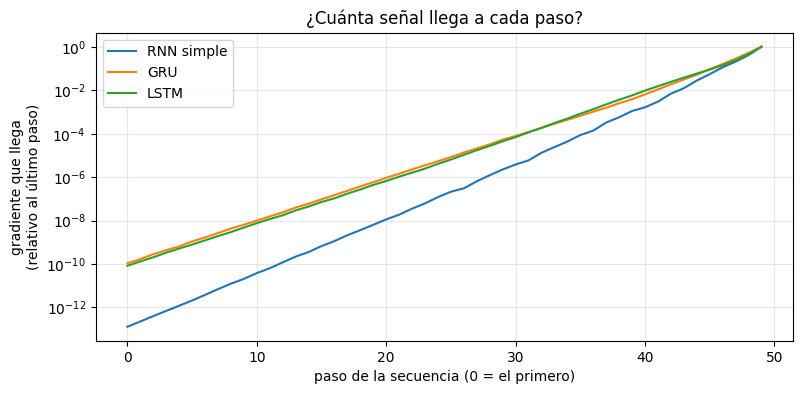

In [4]:
def gradiente_por_paso(red, largo=50, d_in=16, seed=0):
    torch.manual_seed(seed)
    x = torch.randn(32, largo, d_in, requires_grad=True)
    salidas, _ = red(x)
    salidas[:, -1].sum().backward()          # error solo en el ÚLTIMO paso
    g = x.grad.norm(dim=(0, 2))              # tamaño del gradiente en cada paso
    return (g / g[-1]).detach()              # relativo al último paso

torch.manual_seed(0)
redes = {
    "RNN simple": nn.RNN(16, 64, batch_first=True),
    "GRU": nn.GRU(16, 64, batch_first=True),
    "LSTM": nn.LSTM(16, 64, batch_first=True),
}

plt.figure(figsize=(9, 4))
for nombre, red in redes.items():
    plt.semilogy(gradiente_por_paso(red), label=nombre)
plt.xlabel("paso de la secuencia (0 = el primero)")
plt.ylabel("gradiente que llega\n(relativo al último paso)")
plt.title("¿Cuánta señal llega a cada paso?")
plt.legend(); plt.grid(alpha=.3); plt.show()

👀 El eje vertical es **logarítmico**: cada raya es ×10. Al paso 0 llega algo como $10^{-10}$ veces la señal del último paso. Para efectos prácticos: **nada**.

💡 **¿No que la LSTM arreglaba esto?**

La LSTM **puede** mantener la señal, pero solo si su puerta de olvido está cerca de 1. Recién creada (sin entrenar), su puerta de olvido vale ≈ 0.5 en promedio (σ(0) = 0.5), así que también se "olvida". Durante el entrenamiento la red **aprende** a abrir esa puerta cuando le sirve.


### Abrir la puerta de olvido

Ahora "abrimos la puerta de olvido" a mano. En PyTorch, el sesgo de la LSTM tiene 4 bloques de tamaño `hidden_size`, en este orden: **entrada, olvido, candidato, salida**. El bloque de olvido es `[64:128]`.

Con `sesgo_olvido` = 3, la puerta de olvido queda en σ(3) ≈ 0.95. Se puede cambiar el valor para ver el efecto: σ(0) = 0.5, σ(1) ≈ 0.73, σ(5) ≈ 0.99.

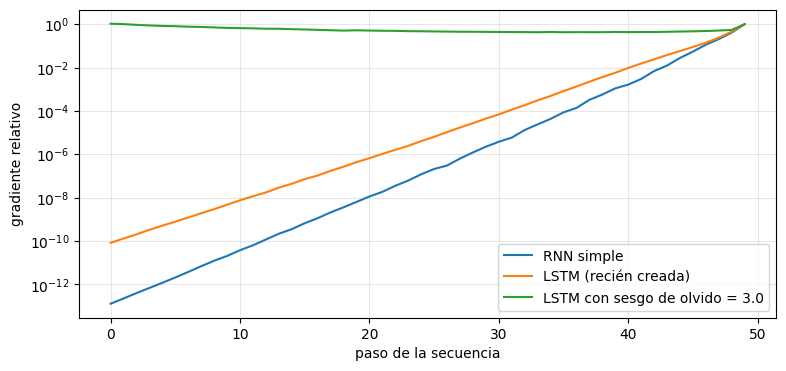

In [5]:
sesgo_olvido = 3.0   # ← probar 0, 1, 3 o 5

torch.manual_seed(0)
lstm_abierta = nn.LSTM(16, 64, batch_first=True)
with torch.no_grad():
    lstm_abierta.bias_ih_l0[64:128].fill_(sesgo_olvido)   # bloque de la puerta de olvido
    lstm_abierta.bias_hh_l0[64:128].fill_(0.0)

plt.figure(figsize=(9, 4))
plt.semilogy(gradiente_por_paso(redes["RNN simple"]), label="RNN simple")
plt.semilogy(gradiente_por_paso(redes["LSTM"]), label="LSTM (recién creada)")
plt.semilogy(gradiente_por_paso(lstm_abierta), label=f"LSTM con sesgo de olvido = {sesgo_olvido}")
plt.xlabel("paso de la secuencia"); plt.ylabel("gradiente relativo")
plt.legend(); plt.grid(alpha=.3); plt.show()

Con la puerta de olvido cerca de 1, la señal llega casi entera desde 50 pasos atrás: es la **cinta transportadora** de la clase funcionando. Por eso en la práctica muchas implementaciones inicializan el sesgo de olvido en 1 o más (Jozefowicz et al., 2015).

---

## 3. Un modelo de lenguaje que escribe como el Quijote

En la clase vimos el truco que lleva a ChatGPT: **predecir el siguiente token**. Vamos a entrenar una LSTM que lee el Quijote **letra por letra** e intenta adivinar la letra siguiente (como el famoso experimento de Karpathy, 2015).

### 3.1 Los datos

In [6]:
import urllib.request

def descargar_quijote():
    urls = ["https://www.gutenberg.org/cache/epub/2000/pg2000.txt",
            "https://gutenberg.pglaf.org/2/0/0/2000/2000-0.txt"]
    for url in urls:
        try:
            crudo = urllib.request.urlopen(url, timeout=30).read().decode("utf-8")
            inicio = crudo.index("\n", crudo.index("*** START")) + 1
            return crudo[inicio:crudo.index("*** END")].strip().replace("\r\n", "\n")
        except Exception as e:
            print("No se pudo con", url, "→", e)
    raise RuntimeError("No se pudo descargar el Quijote")

quijote = descargar_quijote()
print(f"{len(quijote):,} caracteres")
print(quijote[2000:2400])

2,110,726 caracteres
 su
amo, y de la aventura que le sucedió con un cuerpo muerto, con otros
acontecimientos famosos

De la jamás vista ni oída aventura que con más poco
peligro fue acabada de famoso caballero en el mundo, como la que acabó
el valeroso don Quijote de la Mancha

Que trata de la alta aventura y rica ganancia del
yelmo de Mambrino, con otras cosas sucedidas a nuestro invencible
caballero

De la libertad


In [7]:
caracteres = sorted(set(quijote))
V = len(caracteres)
a_id = {c: i for i, c in enumerate(caracteres)}
datos = torch.tensor([a_id[c] for c in quijote])

def a_texto(ids):
    return "".join(caracteres[i] for i in ids)

print(f"Vocabulario: {V} caracteres →", "".join(caracteres))

Vocabulario: 92 caracteres → 
 !"'(),-.01234567:;?ABCDEFGHIJLMNOPQRSTUVWXYZ]abcdefghijlmnopqrstuvxyz¡«»¿ÁÉÍÑÓÚàáéíïñóùúü—


Aquí los tokens son **caracteres** (Idea 2 del notebook 1): vocabulario chico y nunca hay `[UNK]`.

**¿Qué aprende el modelo?** Para cada posición, la entrada es el texto hasta ahí y el objetivo es el **mismo texto corrido en una letra**:

In [8]:
T = 128   # largo de cada ventana de texto

def ventanas(batch=64):
    inicio = torch.randint(0, len(datos) - T - 1, (batch,))
    x = torch.stack([datos[i:i + T] for i in inicio])          # entrada
    y = torch.stack([datos[i + 1:i + T + 1] for i in inicio])  # objetivo: la letra SIGUIENTE en cada posición
    return x.to(device), y.to(device)

x, y = ventanas(1)
print("entrada :", repr(a_texto(x[0, :40].tolist())))
print("objetivo:", repr(a_texto(y[0, :40].tolist())))

entrada : 'esotro que está junto a él.\n\n— Es —dijo '
objetivo: 'sotro que está junto a él.\n\n— Es —dijo e'


### 3.2 El modelo

Embedding → LSTM → capa de salida. La capa de salida da un puntaje (*logit*) para cada uno de los caracteres posibles, en **cada** posición (el patrón "muchos → muchos" de la clase).

In [9]:
class ModeloDeLenguaje(nn.Module):
    def __init__(self, vocab, d_emb=64, d_h=256, tipo="lstm"):
        super().__init__()
        self.emb = nn.Embedding(vocab, d_emb)
        self.rnn = {"lstm": nn.LSTM, "gru": nn.GRU, "rnn": nn.RNN}[tipo](d_emb, d_h, batch_first=True)
        self.salida = nn.Linear(d_h, vocab)

    def forward(self, x, estado=None):
        h, estado = self.rnn(self.emb(x), estado)
        return self.salida(h), estado

torch.manual_seed(0)
modelo = ModeloDeLenguaje(V).to(device)
print(f"{sum(p.numel() for p in modelo.parameters()):,} parámetros")

x, y = ventanas()
logits, _ = modelo(x)
loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))
print(f"loss antes de entrenar: {loss.item():.2f}")

359,260 parámetros
loss antes de entrenar: 4.54


💡 **¿Por qué la loss inicial es ≈ 4.5?**

Sin entrenar, el modelo reparte la probabilidad casi por igual entre los ~90 caracteres: p ≈ 1/V. La cross-entropy es −log(p) = log(V) ≈ log(92) ≈ 4.52. Cualquier cosa por debajo de eso es algo que el modelo **aprendió**.


### 3.3 Generar texto

Para escribir, el modelo predice probabilidades para la siguiente letra, **sorteamos** una, la agregamos y repetimos (la diapositiva "El truco que cambió todo"). La **temperatura** controla qué tan arriesgado es el sorteo.

Las dos líneas clave del sorteo:
1. Convertir los logits en probabilidades con `F.softmax`, **dividiendo antes por la temperatura**.
2. Sortear un índice con `torch.multinomial`.

In [10]:
@torch.no_grad()
def generar(modelo, inicio="En un lugar de la Mancha", n=300, temperatura=1.0):
    modelo.eval()
    ids = torch.tensor([[a_id[c] for c in inicio]], device=device)
    logits, estado = modelo(ids)
    logits = logits[:, -1]
    salida = list(inicio)
    for _ in range(n):
        probs = F.softmax(logits / temperatura, dim=-1)
        siguiente = torch.multinomial(probs, num_samples=1)
        salida.append(caracteres[siguiente.item()])
        logits, estado = modelo(siguiente, estado)
        logits = logits[:, -1]
    modelo.train()
    return "".join(salida)

print("Sin entrenar:", repr(generar(modelo, n=80)))

Sin entrenar: 'En un lugar de la ManchaUÚBàg»BùHJfOFïY6o)J«]j0)jjt5"úF¿veuucvN\nP\'eCpv¿?5yÉ!cqJDX5G?q»p»jlÉX«HdOtÚfoùiY—'


### 3.4 Entrenar

1,500 pasos, mostrando cada tanto lo que escribe el modelo. Hay que mirar cómo **evoluciona**: primero letras al azar, después palabras cortas y espacios, después algo que suena a Quijote.

In [11]:
def entrenar_lm(modelo, pasos=1500, mostrar_cada=500, lr=3e-3):
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr)
    historial = []
    inicio = time.time()
    for paso in range(1, pasos + 1):
        x, y = ventanas()
        logits, _ = modelo(x)
        loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)   # evita que el gradiente explote
        opt.step()
        historial.append(loss.item())
        if mostrar_cada and (paso % mostrar_cada == 0 or paso == 1):
            print(f"── paso {paso} · loss {loss.item():.2f} · {time.time() - inicio:.0f}s ──")
            print(generar(modelo, n=150, temperatura=0.8), "\n")
    return historial

torch.manual_seed(0)
modelo = ModeloDeLenguaje(V, tipo="lstm").to(device)
historial_lstm = entrenar_lm(modelo)

── paso 1 · loss 4.54 · 0s ──
En un lugar de la ManchaUÚBàg»BùHJfOFïY6o)J«]j0)jjt5"úF¿veuucvN
P'eCpv¿?5yÉ!cqJDX5G?q»u»jlÉX«HdOtÚfoùiY—iP1q0xBac?E3—( ü"4Áen—FqQé
,5dM«0ÓHeU6ùR s0úNT
Pb»pgVc
5sBe)¡üÚ-s-fémd 

── paso 500 · loss 1.57 · 10s ──
En un lugar de la Mancha, Paravente, no he bonda: San mi digo que es lo despeja que el mucha saber con el sus brivo que yo mal
encajado el mano, como tierra de habráres, y lo 

── paso 1000 · loss 1.40 · 19s ──
En un lugar de la Mancha, y atenfió las males incomposates y retentaré consedado y le tras aquellos ojos por mil virme a su
ver y ser prometió ecebar, tenía desencajo
en
los  

── paso 1500 · loss 1.34 · 28s ──
En un lugar de la Mancha y para mi
ama que le
dijo a lo que con menos de la comer a la manera, pero no
las tales desdichados, con
otra servir un sadida, y, que decía el señor 



### Jugar con la temperatura

El mismo modelo, con temperaturas 0.2, 0.8 y 1.5. También se puede cambiar el texto de inicio.

In [12]:
for temperatura in [0.2, 0.8, 1.5]:
    print(f"🌡️ temperatura {temperatura}:")
    print(generar(modelo, inicio="—Mire vuestra merced", n=250, temperatura=temperatura), "\n")

🌡️ temperatura 0.2:
—Mire vuestra merced —respondió Sancho—, que es que se le dijo:

— Pues es que lo había de ser la verdad de la verdad que estaban las cosas de la cabeza de la cabeza de la mano de la vida de la mano de la desatenta de la mano de la cabeza de la mano de la cual la hermos 

🌡️ temperatura 0.8:
—Mire vuestra merced que don Quijote de la corte a desperador de vosieron una
hallado el rico alguno de renor, de don Quijote manarle del parte de Dios por don Berde de mi ya y como lo
que él lo perseguilla de su despirar a los que
las destribases, y, aunque se diga al  

🌡️ temperatura 1.5:
—Mire vuestra merced
y últó Són DenE si Dios otro que Lon firte.

— ¡a-, amara;
el rigolas, penrá y
nuesó otoroso, y que
podqueño emprimicubelo recabada
Robillencia, Sancho, érigos, mayoren gáramente—.

»— ¿Saculo. Quedó por cabeda etieremos eviese; perá, puesto, él hac 



💡 **Qué se ve**

- **Temperatura baja**: casi siempre la letra más probable. Texto "seguro" pero repetitivo (suele quedarse en loops como "de la de la…").
- **Temperatura alta**: la distribución se aplana. Más variedad, pero aparecen palabras inventadas y letras raras.

Así funcionan también los chatbots. Lo único distinto es el tamaño del modelo y que el "motor" es un Transformer en vez de una LSTM.


💡 **Para destacar:** el modelo aprendió a cerrar comillas, poner mayúscula después de un punto y abrir diálogos con "—", sin que nadie le explicara ortografía. Solo predijo la siguiente letra millones de veces.

---

## ⭐ Extra: ¿y una RNN simple?

Entrenamos una `nn.RNN` con el mismo presupuesto y comparamos las curvas de la loss.

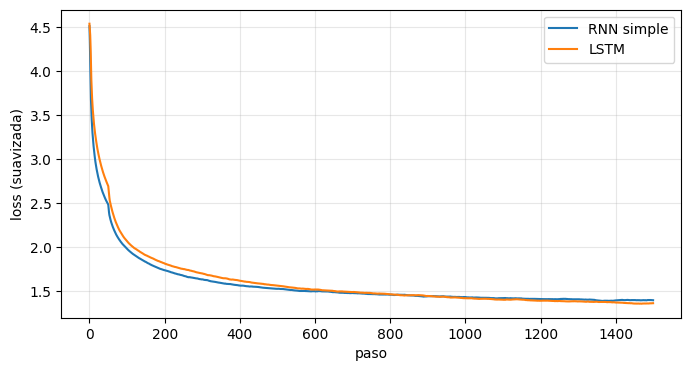

En un lugar de la Mancha a Sancho Panza le prometer cantado caballeros andantes nosotros los que se lierra, se acabar, ni pensara adelante
en qué quedaron por
cuál con son mucho pasas y confuesto, con la mendados, le dejaron a dar, entre su lejalamente esto había percienda 


In [13]:
torch.manual_seed(0)
modelo_rnn = ModeloDeLenguaje(V, tipo="rnn").to(device)
historial_rnn = entrenar_lm(modelo_rnn, mostrar_cada=None)   # sin mostrar texto en el camino

def suavizar(xs, k=50):
    return [sum(xs[max(0, i - k):i + 1]) / len(xs[max(0, i - k):i + 1]) for i in range(len(xs))]

plt.figure(figsize=(8, 4))
plt.plot(suavizar(historial_rnn), label="RNN simple")
plt.plot(suavizar(historial_lstm), label="LSTM")
plt.xlabel("paso"); plt.ylabel("loss (suavizada)"); plt.legend(); plt.grid(alpha=.3); plt.show()
print(generar(modelo_rnn, n=250, temperatura=0.8))

💡 **¿Por qué la RNN simple no queda tan atrás?**

Para predecir la siguiente **letra**, casi todo lo que importa está muy cerca (las letras anteriores de la misma palabra), así que la memoria corta de la RNN alcanza. La ventaja de la LSTM aparece cuando la dependencia es **larga**: cerrar una comilla abierta hace 80 caracteres, o conjugar "estaban" acordándose de "los perros" del principio de la oración. Prueba subir `T` y entrenar más pasos.

---

## ✅ Resumen

| | Lo que vimos |
|---|---|
| RNN | Es un `for` loop: los **mismos pesos** en cada paso, solo cambia la memoria `h` |
| Gradientes | **Medimos** cómo se desvanecen, y cómo una puerta de olvido ≈ 1 deja pasar la señal |
| Modelo de lenguaje | Una LSTM que **predice la siguiente letra** y escribe como el Quijote |

➡️ En el **notebook 3**: ¿y si la salida es **otra secuencia**, como en una traducción? Encoder–decoder y atención.